In [1]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 
warnings.filterwarnings('ignore')

In [2]:
data  = pd.read_csv(r"C:\Users\navee\Desktop\python libraries\Projects series\Bank_Loan_Risk_Analytics\Data\Banking Credit Risk Analytics raw_dataset.csv")
df = data.copy()


## Dataset Columns and Their Description

| Column | What It Represents |
|---|---|
| `person_age` | Applicant's age |
| `person_income` | Applicant's income |
| `person_home_ownership` | Home ownership status, e.g., RENT, OWN, MORTGAGE |
| `person_emp_length` | Number of years of employment |
| `loan_intent` | Purpose of taking the loan |
| `loan_grade`  | Loan grade, e.g., A, B, C |
| `loan_amnt`  | Loan amount |
| `loan_int_rate` | Loan interest rate |
| `loan_status`  | 0 = Non-default, 1 = Default |
| `loan_percent_income` | Loan amount as a proportion of income |
| `cb_person_default_on_file` | Whether a previous default is recorded in credit history |
| `cb_person_cred_hist_length` | Length of the applicant's credit history in years |


### understand data 

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
# Dataset Shape 
print('Dataset Shape : ', df.shape)
# Data Type of each columns 
print('\nData types: ')
print(df.dtypes)
# Missing Values
print('\nMissing values:')
print(df.isnull().sum())
# Duplicated Values 
print('\nDuplicated Values:')
print(df.duplicated().sum())

Dataset Shape :  (32581, 12)

Data types: 
person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

Missing values:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Duplicated Values:
165


In [5]:
# Missing values
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing/len(df)*100).round(2)
})
display(missing_report.sort_values(
    by = "Missing_Percentage",
    ascending = False
))

,Missing_Count,Missing_Percentage
loan_int_rate,3116,9.56
person_emp_length,895,2.75
person_age,0,0.00
person_income,0,0.00
person_home_ownership,0,0.00
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_status,0,0.00
loan_percent_income,0,0.00


- Summary of Data 

In [6]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


- Missing values check 

In [7]:
miss = df.isnull().sum()
miss_repo = pd.DataFrame({
    "Missing_total": miss
})

display(miss_repo.sort_values(
    by = "Missing_total",
    ascending=False
    
))

,Missing_total
loan_int_rate,3116
person_emp_length,895
person_age,0
person_income,0
person_home_ownership,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0


In [8]:
# cheking weather mean is better for fill the missing values in person_emp_length column or median 
print('Mean of person_emp_length column:',df['person_emp_length'].mean().round(2))
print('Median of person_emp_length column:',df['person_emp_length'].median())

Mean of person_emp_length column: 4.79
Median of person_emp_length column: 4.0


In [9]:
# Fill missing values in person_emp_length column 
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())

In [10]:
# fill missing values in loan_int_rate (Loan interest rate)
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].mean())

In [11]:
miss_values = df.isnull().sum()
report_ = pd.DataFrame({
    'count': miss_values
})

display(report_.sort_values(
    by = 'count',
    ascending=False
))

,count
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


In [12]:
# Remove Duplicated valuees
df.duplicated().sum()

np.int64(165)

In [13]:
# check duplicate rows 
display(df[df.duplicated(keep=False)])

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
14,23,115000,RENT,2.0,EDUCATION,A,35000,7.900000,0,0.30,N,4
238,22,183000,MORTGAGE,3.0,EDUCATION,A,1000,11.011695,0,0.01,N,2
252,24,85000,RENT,5.0,MEDICAL,B,25000,10.620000,0,0.29,N,4
591,26,20000,MORTGAGE,5.0,MEDICAL,A,4800,5.990000,0,0.24,N,3
740,21,21600,OWN,4.0,VENTURE,A,7125,6.990000,0,0.33,N,3
...,...,...,...,...,...,...,...,...,...,...,...,...
32010,42,39996,MORTGAGE,2.0,HOMEIMPROVEMENT,A,2500,5.420000,0,0.06,N,12
32047,36,250000,RENT,2.0,DEBTCONSOLIDATION,A,20000,7.880000,0,0.08,N,17
32172,49,120000,MORTGAGE,12.0,MEDICAL,B,12000,10.990000,0,0.10,N,12
32259,39,40000,OWN,4.0,VENTURE,B,1000,10.370000,0,0.03,N,16


In [14]:
# Show the percentage of duplicated data 
duplicate_count = df.duplicated().sum() 
percentage = ((duplicate_count / len(df))*100).round(2)
print(f'Duplicated data count : {duplicate_count}')
print(f"Percentage of duplicated data: {percentage}")

Duplicated data count : 165
Percentage of duplicated data: 0.51


In [16]:
# remove duplicate data 
df = df.drop_duplicates()

### Data Quality Check 

In [17]:
# Check unusual ages
print("Age above 100:", (df['person_age'] > 100).sum())

# Check unusual employment length
print('Employments above 50 years: ', (df['person_emp_length'] > 50).sum())

# Check invalid income
print('Emplooyees whose Income <= 0: ', (df['person_income'] <= 0).sum())

# Check invalid loan amount
print('Loan Amount <= 0: ', (df['loan_amnt'] <= 0).sum())

# Check target values
print("\nloan status values")
print(df['loan_status'].value_counts())

Age above 100: 5
Employments above 50 years:  2
Emplooyees whose Income <= 0:  0
Loan Amount <= 0:  0

loan status values
loan_status
0    25327
1     7089
Name: count, dtype: int64


In [18]:
numerical_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

display(df[numerical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
person_age,32416.0,27.747008,6.354100,20.00,23.00,26.000000,30.00,144.00
person_income,32416.0,66091.640826,62015.580269,4000.00,38542.00,55000.000000,79218.00,6000000.00
person_emp_length,32416.0,4.768880,4.090411,0.00,2.00,4.000000,7.00,123.00
loan_amnt,32416.0,9593.845632,6322.730241,500.00,5000.00,8000.000000,12250.00,35000.00
loan_int_rate,32416.0,11.016733,3.083040,5.42,8.49,11.011695,13.11,23.22
loan_percent_income,32416.0,0.170250,0.106812,0.00,0.09,0.150000,0.23,0.83
cb_person_cred_hist_length,32416.0,5.811297,4.059030,2.00,3.00,4.000000,8.00,30.00


In [19]:
# Customers with age above 100
print('Customers with age above 100')
display(df[df["person_age"] > 100])
print('\n')
# Employment length above 50 years
print('Employment length above 50 years')
display(df[df["person_emp_length"] > 50])
print('\n')
# Annual income above 1 million
print('Annual income above 1 million')
display(
    df[df["person_income"] > 1_000_000]
)

Customers with age above 100


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.570000,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.860000,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.250000,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,11.011695,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.730000,0,0.00,N,25




Employment length above 50 years


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4




Annual income above 1 million


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
17833,32,1200000,MORTGAGE,1.0,VENTURE,A,12000,7.510000,0,0.01,N,8
29119,36,1200000,OWN,16.0,MEDICAL,A,10000,6.540000,0,0.01,N,11
29120,40,1200000,MORTGAGE,1.0,MEDICAL,A,10000,11.011695,0,0.01,N,16
30049,42,2039784,RENT,0.0,VENTURE,C,8450,12.290000,0,0.00,Y,15
31922,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.740000,0,0.00,N,17
31924,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.400000,0,0.00,N,15
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.730000,0,0.00,N,25
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.270000,0,0.01,N,30
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,11.011695,0,0.00,N,21


### Handle Invalid ages aur employment lengths 

In [20]:
import numpy as np

df_clean = df.copy()

# Count suspicious values before handling
print("Invalid ages:", (df_clean["person_age"] > 100).sum())
print("Invalid employment lengths:",
      (df_clean["person_emp_length"] > 50).sum())

# Mark suspicious values as missing
df_clean.loc[
    df_clean["person_age"] > 100, "person_age"
] = np.nan

df_clean.loc[
    df_clean["person_emp_length"] > 50, "person_emp_length"
] = np.nan

print("\nRemaining suspicious ages:",
      (df_clean["person_age"] > 100).sum())

print("Remaining suspicious employment lengths:",
      (df_clean["person_emp_length"] > 50).sum())

Invalid ages: 5
Invalid employment lengths: 2

Remaining suspicious ages: 0
Remaining suspicious employment lengths: 0


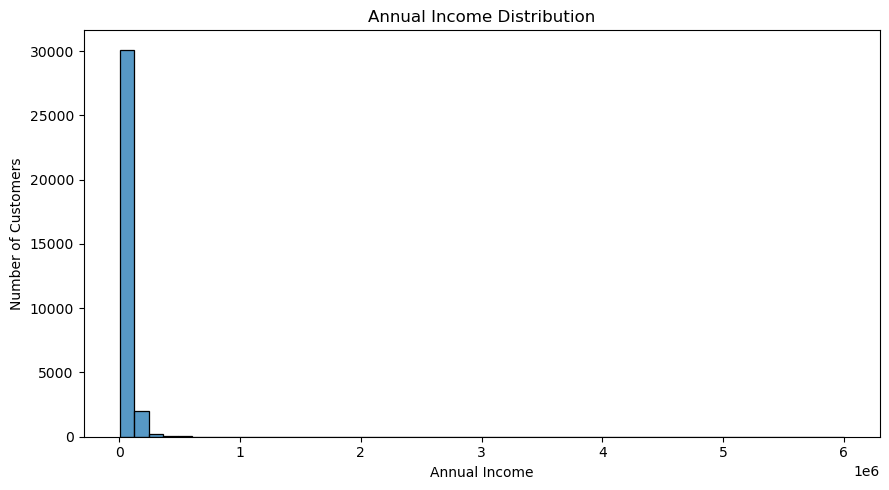

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="person_income",
    bins=50
)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [22]:
grade_analysis = (
    df_clean.groupby("loan_grade")
    .agg(
        total_loans=("loan_status", "count"),
        defaults=("loan_status", "sum"),
        default_rate=("loan_status", "mean")
    )
)

grade_analysis["default_rate"] *= 100

display(
    grade_analysis.sort_values(
        "default_rate",
        ascending=False
    ).round(2)
)

,total_loans,defaults,default_rate
loan_grade,,,
G,64,63,98.44
F,241,170,70.54
E,963,621,64.49
D,3620,2138,59.06
C,6438,1336,20.75
B,10387,1695,16.32
A,10703,1066,9.96


- Which home ownership category has the highest loan default rate?

In [23]:
home_analysis = (
    df_clean.groupby("person_home_ownership")
    .agg(
        total_loans=("loan_status", "count"),
        defaults=("loan_status", "sum"),
        default_rate=("loan_status", "mean")
    )
)

home_analysis["default_rate"] *= 100

display(
    home_analysis.sort_values(
        "default_rate",
        ascending=False
    ).round(2)
)

,total_loans,defaults,default_rate
person_home_ownership,,,
RENT,16378,5177,31.61
OTHER,106,33,31.13
MORTGAGE,13369,1687,12.62
OWN,2563,192,7.49


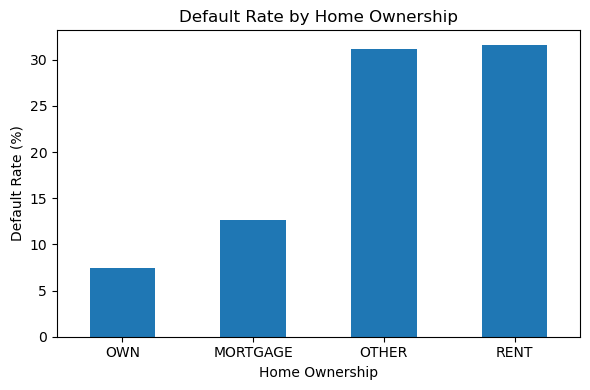

In [24]:
home_analysis["default_rate"].sort_values().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Business insights — of that output?

1. RENT has the highest default rate among the large categories.
2. OWN has the lowest default rate.
3. MORTGAGE has a 12.62% default rate.
4. Be careful with OTHER.


- Which home loan_intent category has the highest loan default rate and how loan purpose releted with default rate ?

In [25]:
intent_analysis = (
    df_clean.groupby("loan_intent")
    .agg(
        total_loans=("loan_status", "count"),
        defaults=("loan_status", "sum"),
        default_rate=("loan_status", "mean")
    )
)

intent_analysis["default_rate"] *= 100

display(
    intent_analysis
    .sort_values("default_rate", ascending=False)
    .round(2)
)

,total_loans,defaults,default_rate
loan_intent,,,
DEBTCONSOLIDATION,5189,1488,28.68
MEDICAL,6042,1617,26.76
HOMEIMPROVEMENT,3594,940,26.15
PERSONAL,5498,1094,19.90
EDUCATION,6411,1106,17.25
VENTURE,5682,844,14.85


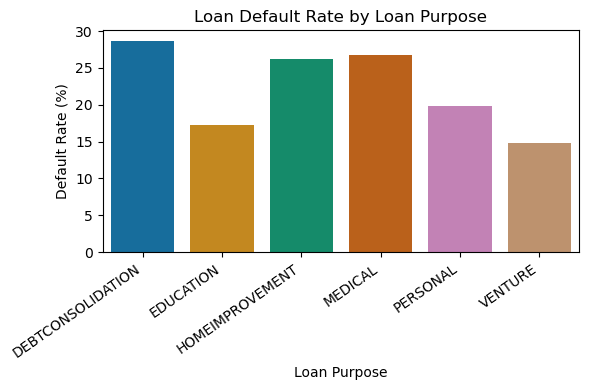

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.barplot(
    x=intent_analysis.index,
    y=intent_analysis["default_rate"],
    palette='colorblind'
)

plt.title("Loan Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



## EDA 
### Step 1: Distribution of Numerical Data 

- Identify Numrical Columns 

In [27]:
# Select numerical columns
numerical_cols = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns

print(numerical_cols)

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')


- show the summary of Numrical columns 

In [28]:
df_clean[numerical_cols].describe().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32411.00,32416.00,32414.00,32416.00,32416.00,32416.00,32416.00,32416.00
mean,27.73,66091.64,4.76,9593.85,11.02,0.22,0.17,5.81
std,6.21,62015.58,3.98,6322.73,3.08,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38542.00,2.00,5000.00,8.49,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,11.01,0.00,0.15,4.00
75%,30.00,79218.00,7.00,12250.00,13.11,0.00,0.23,8.00
max,94.00,6000000.00,41.00,35000.00,23.22,1.00,0.83,30.00


- Make the chart of every numrical columns 

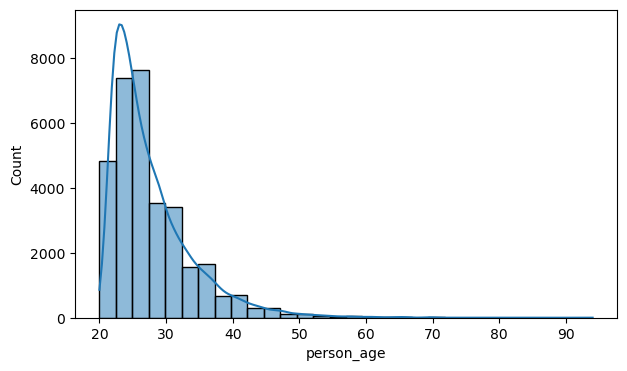

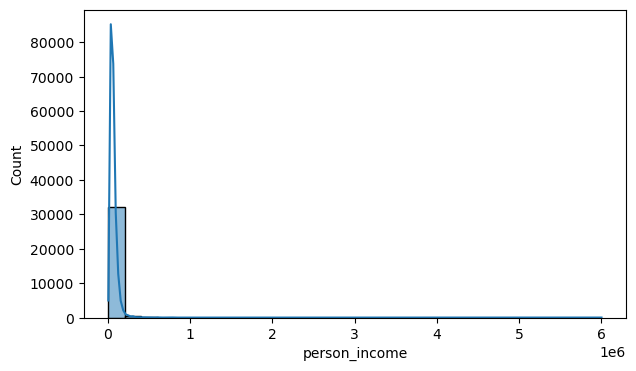

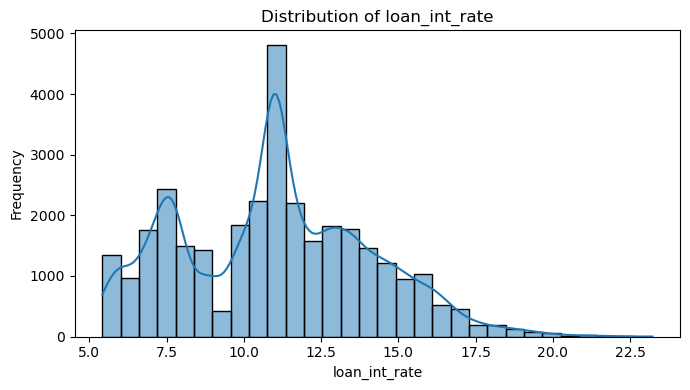

In [29]:
columns_to_plot = [
    "person_age",
    "person_income",
    "loan_int_rate"]
for col in columns_to_plot:
    plt.figure(figsize = (7,4))
    sns.histplot(
        data=df_clean,
        x = col,
        bins = 30,
        kde = True )
plt.title(f'Distribution of {col}')
plt.xlabel(col)
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### EDA questions to analyze  Bank & Loan Risk Analytics dataset 

In [30]:
# Q1. Display the number of rows and columns in the dataset.
rows_count = df.shape
print(f"Number of rows: {rows_count[0]}")
print(f"Number of Columns: {rows_count[1]}")

Number of rows: 32416
Number of Columns: 12


In [31]:
# Q2. Display all column names and their data types.
df.info ()

<class 'pandas.core.frame.DataFrame'>
Index: 32416 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32416 non-null  int64  
 1   person_income               32416 non-null  int64  
 2   person_home_ownership       32416 non-null  object 
 3   person_emp_length           32416 non-null  float64
 4   loan_intent                 32416 non-null  object 
 5   loan_grade                  32416 non-null  object 
 6   loan_amnt                   32416 non-null  int64  
 7   loan_int_rate               32416 non-null  float64
 8   loan_status                 32416 non-null  int64  
 9   loan_percent_income         32416 non-null  float64
 10  cb_person_default_on_file   32416 non-null  object 
 11  cb_person_cred_hist_length  32416 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.2+ MB


In [32]:
# Find the minimum, maximum, and average loan amount
print(f'Max loan amount: {df['loan_amnt'].max()}')
print(f'Min Loan amount: {df['loan_amnt'].min()}')
print(f'AVG loan amount: {df['loan_amnt'].mean().round(2)}')

Max loan amount: 35000
Min Loan amount: 500
AVG loan amount: 9593.85


In [33]:
# Find the average interest rate and median interest rate.
intrest_rate = df_clean['loan_int_rate']
print(f'AVG Intrest Rate: {df_clean['loan_int_rate'].mean().round(2)}')
print(f'median Intrest Rate: {df_clean['loan_int_rate'].median()}') 

AVG Intrest Rate: 11.02
median Intrest Rate: 11.011694892245037


In [34]:
# Count the number of default and non-default loans.
count_loan_stts = df_clean['loan_status'].value_counts()
display(count_loan_stts)

loan_status
0    25327
1     7089
Name: count, dtype: int64

In [35]:
# Calculate the percentage of default and non-default loans.
percent_default = (count_loan_stts/len(df_clean)) * 100
print(percent_default)

loan_status
0    78.13117
1    21.86883
Name: count, dtype: float64


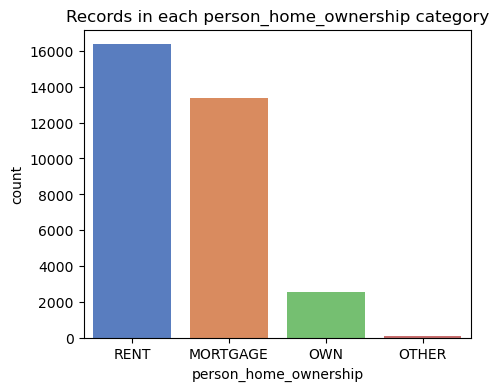

In [36]:
# Count the records in each person_home_ownership category and visulize it into graph
own_rec = df_clean['person_home_ownership'].value_counts()
plt.figure(figsize=(5,4))
sns.barplot(own_rec, palette='muted')
plt.title("Records in each person_home_ownership category")
plt.show()

In [37]:
# Count the records in each loan_intent category.
loan_intent = df_clean['loan_intent'].value_counts()
loan_intent

loan_intent
EDUCATION            6411
MEDICAL              6042
VENTURE              5682
PERSONAL             5498
DEBTCONSOLIDATION    5189
HOMEIMPROVEMENT      3594
Name: count, dtype: int64

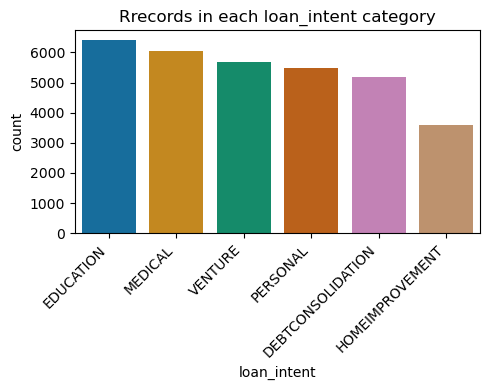

In [38]:
plt.figure(figsize=(5,4))
sns.barplot(loan_intent, palette='colorblind')
plt.title("Rrecords in each loan_intent category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [39]:
# Find borrowers whose income is greater than 100,000.
inc = df_clean[df_clean['person_income'] > 100000]
inc

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
13,26.0,108160,RENT,4.0,EDUCATION,E,35000,18.39,1,0.32,N,4
14,23.0,115000,RENT,2.0,EDUCATION,A,35000,7.90,0,0.30,N,4
15,23.0,500000,MORTGAGE,7.0,DEBTCONSOLIDATION,B,30000,10.65,0,0.06,N,3
16,23.0,120000,RENT,0.0,EDUCATION,A,35000,7.90,0,0.29,N,4
18,23.0,113000,RENT,8.0,DEBTCONSOLIDATION,D,35000,18.25,1,0.31,N,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32551,58.0,780000,MORTGAGE,7.0,PERSONAL,A,4500,6.91,0,0.01,N,19
32561,54.0,129000,MORTGAGE,6.0,EDUCATION,B,9000,11.49,1,0.07,N,24
32562,61.0,160000,MORTGAGE,30.0,PERSONAL,B,24000,10.38,0,0.15,N,21
32577,54.0,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19


In [40]:
# Find loans with a loan amount greater than 15,000.
loan_amt = df_clean[df_clean['loan_amnt']>15000]
loan_amt

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22.0,59000,RENT,NaN,PERSONAL,D,35000,16.02,1,0.59,Y,3
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
6,26.0,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24.0,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32562,61.0,160000,MORTGAGE,30.0,PERSONAL,B,24000,10.38,0,0.15,N,21
32571,60.0,45600,RENT,1.0,VENTURE,B,20000,10.00,1,0.44,N,26
32574,52.0,65004,RENT,4.0,PERSONAL,D,20000,15.58,1,0.31,Y,19
32577,54.0,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19


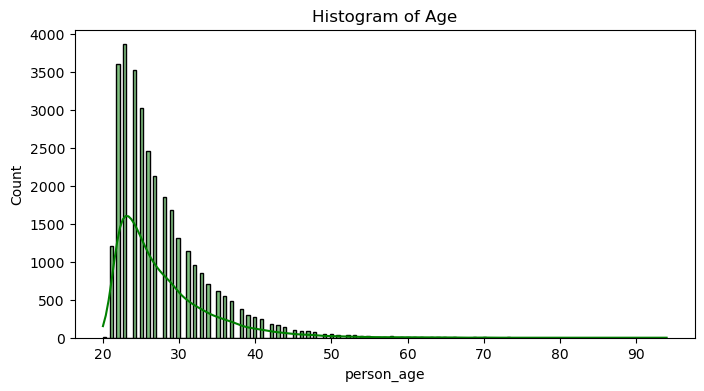

In [41]:
# Create a histogram of person_age.
plt.figure(figsize=(8,4))
sns.histplot(
    data = df_clean,
    x = 'person_age',
    kde = True, 
    color='g',
    linewidth = 1
)
plt.title("Histogram of Age")
plt.show()

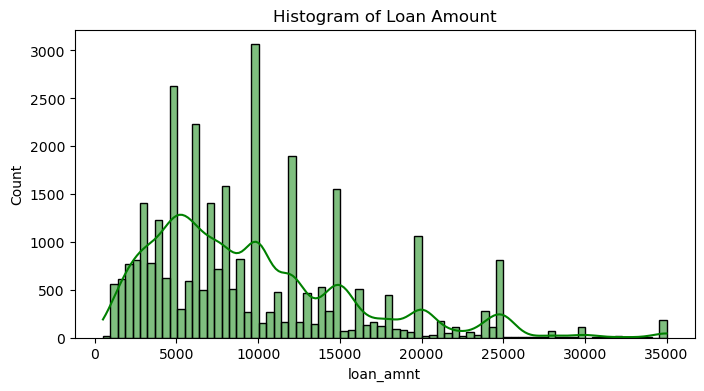

In [42]:
#Create a histogram of loan_amnt
plt.figure(figsize=(8,4))
sns.histplot(
    data = df_clean,
    x = 'loan_amnt',
    kde = True, 
    color='g',
    linewidth = 1
)
plt.title("Histogram of Loan Amount")
plt.show()

In [43]:
# Calculate total loans, defaults, and default rate for each loan_intent.
result = df_clean.groupby('loan_intent').agg(
    total_loan=('loan_status','count'),
    defaults=('loan_status','sum'),
    default_rate=('loan_status','mean')
)

result['default_rate'] = result['default_rate']*100
result


,total_loan,defaults,default_rate
loan_intent,,,
DEBTCONSOLIDATION,5189,1488,28.676045
EDUCATION,6411,1106,17.251599
HOMEIMPROVEMENT,3594,940,26.154702
MEDICAL,6042,1617,26.762661
PERSONAL,5498,1094,19.898145
VENTURE,5682,844,14.853925


In [44]:
# Calculate total loans, defaults, and default rate for each person_home_ownership category.
reslt = df_clean.groupby('person_home_ownership').agg(
    total_loan = ('loan_status','count'),
    defaults = ('loan_status','sum'),
    default_rate = ('loan_status','mean')
)
reslt['default_rate'] = (reslt['default_rate']*100).round(2)
reslt

,total_loan,defaults,default_rate
person_home_ownership,,,
MORTGAGE,13369,1687,12.62
OTHER,106,33,31.13
OWN,2563,192,7.49
RENT,16378,5177,31.61


In [45]:
# Calculate the default rate for each loan_grade and sort it from highest to lowest.
loan_g = df_clean.groupby('loan_grade')['loan_status'].mean()*100
loan_g = loan_g.sort_values(ascending=False)
loan_g

loan_grade
G    98.437500
F    70.539419
E    64.485981
D    59.060773
C    20.751786
B    16.318475
A     9.959824
Name: loan_status, dtype: float64

In [46]:
# Calculate the default rate for each age group: 20–25, 26–35, 36–50, and above 50

# step 1 ❯❯❯❯ Craete the age groups 
bins = [19,25,35,50, float('inf')]
labels = ["20-25", "26-35", "36-50", "Above 50"]
df_clean['Age_Group'] = pd.cut(
    df_clean['person_age'],
    bins = bins,
    labels = labels
)

In [47]:
age_default_rate = df_clean.groupby(
    "Age_Group", observed=False
)["loan_status"].mean() * 100

age_default_rate

Age_Group
20-25       23.135454
26-35       20.691416
36-50       20.554855
Above 50    25.795053
Name: loan_status, dtype: float64

In [48]:
df_clean[["person_age", "Age_Group"]].head(10)

,person_age,Age_Group
0,22.0,20-25
1,21.0,20-25
2,25.0,20-25
3,23.0,20-25
4,24.0,20-25
5,21.0,20-25
6,26.0,26-35
7,24.0,20-25
8,24.0,20-25
9,21.0,20-25


In [49]:
# Compare average person_income between default and non-default borrowers a
avg_incm = df_clean.groupby("loan_status")["person_income"].mean()
avg_incm.index = ['Non-Default','Default']
avg_incm

Non-Default    70849.122794
Default        49094.497955
Name: person_income, dtype: float64

In [50]:
# Compare average loan_amnt between default and non-default borrowers
avg_loan_amnt = df_clean.groupby('loan_status')['loan_amnt'].mean()
avg_loan_amnt.index = ['Non-Default','Default']
avg_loan_amnt

Non-Default     9240.155763
Default        10857.479898
Name: loan_amnt, dtype: float64

In [51]:
# Calculate the default rate for each cb_person_default_on_file category
d_r = df_clean.groupby('cb_person_default_on_file')['loan_status'].mean()*100
d_r

cb_person_default_on_file
N    18.432886
Y    37.870855
Name: loan_status, dtype: float64

In [52]:
# Calculate the default rate for each person_home_ownership and loan_intent combination
a = df_clean.groupby(['person_home_ownership','loan_intent'])['loan_status'].mean()*100
a.reset_index()

,person_home_ownership,loan_intent,loan_status
0,MORTGAGE,DEBTCONSOLIDATION,19.495213
1,MORTGAGE,EDUCATION,8.282209
2,MORTGAGE,HOMEIMPROVEMENT,13.741339
3,MORTGAGE,MEDICAL,21.579431
4,MORTGAGE,PERSONAL,9.055794
5,MORTGAGE,VENTURE,4.678363
6,OTHER,DEBTCONSOLIDATION,47.058824
7,OTHER,EDUCATION,35.294118
8,OTHER,HOMEIMPROVEMENT,25.000000
9,OTHER,MEDICAL,41.176471


In [53]:
# Identify the 10 borrowers with the highest loan_percent_income values
top_10 = df_clean.sort_values(
    by="loan_percent_income",
    ascending=False
).head(10)

top_10

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Age_Group
640,22.0,20000,MORTGAGE,0.0,PERSONAL,B,16600,9.76,0,0.83,N,3,20-25
23727,32.0,12000,RENT,1.0,MEDICAL,A,9325,8.38,1,0.78,N,6,26-35
571,21.0,19500,MORTGAGE,0.0,EDUCATION,B,15000,9.64,1,0.77,N,2,20-25
577,26.0,26000,RENT,10.0,EDUCATION,B,20050,9.76,1,0.77,N,2,26-35
18203,30.0,32004,RENT,1.0,PERSONAL,B,24250,11.12,1,0.76,N,5,26-35
460,24.0,18000,OWN,6.0,PERSONAL,A,13000,7.88,1,0.72,N,3,20-25
27878,33.0,10080,OWN,11.0,VENTURE,A,7200,6.03,1,0.71,N,8,26-35
10007,21.0,13000,RENT,0.0,DEBTCONSOLIDATION,C,9250,12.53,1,0.71,N,3,20-25
2452,25.0,32004,MORTGAGE,3.0,PERSONAL,A,22750,6.17,0,0.71,N,4,20-25
18672,28.0,24000,RENT,5.0,MEDICAL,D,16750,14.96,1,0.70,Y,10,26-35


-  Find possible outliers in person_income using the IQR method.

In [54]:
# Step 1: Q1, Q3 aur IQR calculate
Q1 = df_clean["person_income"].quantile(0.25)
Q3 = df_clean["person_income"].quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 38542.0
Q3: 79218.0
IQR: 40676.0


In [55]:
# Step 2: Lower aur Upper limits calculate 
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -22472.0
Upper Limit: 140232.0


In [56]:
# Step 3: Outliers find karo
income_outliers = df_clean[
    (df_clean["person_income"] < lower_limit) |
    (df_clean["person_income"] > upper_limit)
]

income_outliers

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Age_Group
15,23.0,500000,MORTGAGE,7.0,DEBTCONSOLIDATION,B,30000,10.650000,0,0.06,N,3,20-25
20,25.0,162500,RENT,2.0,VENTURE,A,35000,7.490000,0,0.22,N,4,20-25
33,25.0,306000,RENT,2.0,DEBTCONSOLIDATION,C,24250,13.850000,0,0.08,N,3,20-25
34,26.0,300000,MORTGAGE,10.0,MEDICAL,C,7800,13.490000,0,0.03,N,4,26-35
42,26.0,300000,MORTGAGE,10.0,VENTURE,A,20000,7.880000,0,0.07,N,4,26-35
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32544,58.0,780000,MORTGAGE,7.0,PERSONAL,A,4500,6.910000,0,0.01,N,20,Above 50
32546,60.0,1900000,MORTGAGE,5.0,PERSONAL,A,1500,11.011695,0,0.00,N,21,Above 50
32551,58.0,780000,MORTGAGE,7.0,PERSONAL,A,4500,6.910000,0,0.01,N,19,Above 50
32562,61.0,160000,MORTGAGE,30.0,PERSONAL,B,24000,10.380000,0,0.15,N,21,Above 50


In [57]:
# Step 4: Total outliers count karo
print('Total Outliers = ',income_outliers.shape[0])

Total Outliers =  1478


- Find possible outliers in loan_amnt using the IQR method.


In [58]:
q1 = df_clean['loan_amnt'].quantile(0.25)
q3 = df_clean['loan_amnt'].quantile(0.75)
iqr = q3-q1
Lower_limit = q1 - 1.5 * iqr
Upper_limit = q3 + 1.5 * iqr
Loan_amount_outliers = df_clean[
    (df_clean['loan_amnt'] < Lower_limit) |
    (df_clean['loan_amnt'] > Upper_limit)
]
Loan_amount_outliers

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Age_Group
0,22.0,59000,RENT,NaN,PERSONAL,D,35000,16.02,1,0.59,Y,3,20-25
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2,20-25
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,20-25
6,26.0,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3,26-35
7,24.0,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4,20-25
...,...,...,...,...,...,...,...,...,...,...,...,...,...
32524,51.0,120000,MORTGAGE,2.0,PERSONAL,A,30000,7.90,0,0.25,N,22,Above 50
32539,61.0,148000,MORTGAGE,30.0,DEBTCONSOLIDATION,B,24000,10.38,1,0.16,N,20,Above 50
32541,52.0,163000,MORTGAGE,9.0,PERSONAL,D,25000,14.11,1,0.15,N,30,Above 50
32562,61.0,160000,MORTGAGE,30.0,PERSONAL,B,24000,10.38,0,0.15,N,21,Above 50


In [59]:
# Create a bar chart showing default rate by loan_intent.
default_ratee = df_clean.groupby('loan_intent')['loan_status'].mean()*100
default_ratee

loan_intent
DEBTCONSOLIDATION    28.676045
EDUCATION            17.251599
HOMEIMPROVEMENT      26.154702
MEDICAL              26.762661
PERSONAL             19.898145
VENTURE              14.853925
Name: loan_status, dtype: float64

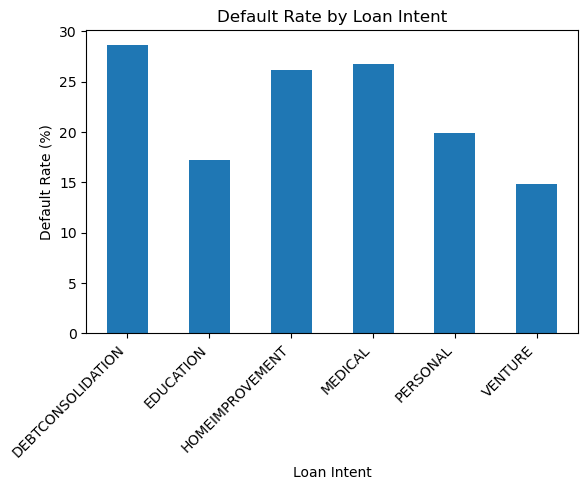

In [60]:
plt.figure(figsize=(6, 5))
default_ratee.plot(kind="bar")
plt.title("Default Rate by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [61]:
# Create a bar chart showing default rate by loan_grade
DR_loan_grade = df_clean.groupby('loan_grade')['loan_status'].mean()*100
DR_loan_grade

loan_grade
A     9.959824
B    16.318475
C    20.751786
D    59.060773
E    64.485981
F    70.539419
G    98.437500
Name: loan_status, dtype: float64

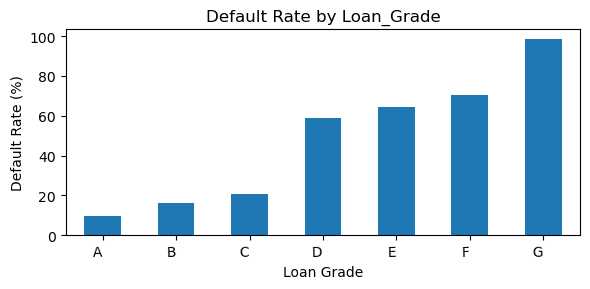

In [62]:
plt.figure(figsize=(6,3))
#sns.barplot(data=df, x = DR_loan_grade.index, y= DR_loan_grade.values)
DR_loan_grade.plot(kind='bar')
plt.title("Default Rate by Loan_Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=2, ha="right")
plt.tight_layout()
plt.show()

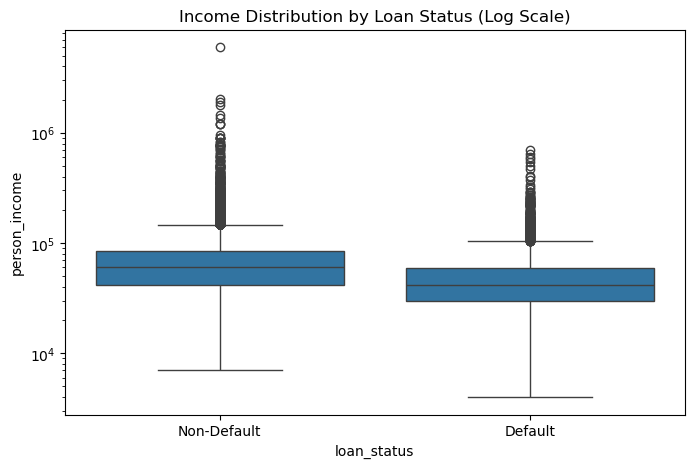

In [65]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="loan_status", y="person_income")

plt.yscale("log")

plt.xticks([0, 1], ["Non-Default", "Default"])
plt.title("Income Distribution by Loan Status (Log Scale)")

plt.show()

###  In above boxplot there is so many outliers so we must check these values are genuine or not 
- Step 1: Highest income records check

In [66]:
high_income = df_clean.sort_values(by = "person_income", ascending=False).head(20)
high_income[[
    "person_age",
    "person_income",
    "person_emp_length",
    "person_home_ownership",
    "loan_amnt",
    "loan_percent_income",
    "loan_status"
]]

,person_age,person_income,person_emp_length,person_home_ownership,loan_amnt,loan_percent_income,loan_status
32297,NaN,6000000,12.0,MORTGAGE,5000,0.00,0
30049,42.0,2039784,0.0,RENT,8450,0.00,0
32546,60.0,1900000,5.0,MORTGAGE,1500,0.00,0
32497,63.0,1782000,13.0,RENT,12025,0.01,0
31924,44.0,1440000,7.0,MORTGAGE,6400,0.00,0
31922,47.0,1362000,9.0,MORTGAGE,6600,0.00,0
29119,36.0,1200000,16.0,OWN,10000,0.01,0
17833,32.0,1200000,1.0,MORTGAGE,12000,0.01,0
29120,40.0,1200000,1.0,MORTGAGE,10000,0.01,0
17834,34.0,948000,18.0,MORTGAGE,2000,0.00,0


- Step 2: Analyze only records who are more then 1 million 

In [67]:
high_income_records = df_clean[
    df_clean["person_income"] > 1000000
]

high_income_records[[
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "loan_status"
]]

,person_age,person_income,person_emp_length,loan_amnt,loan_percent_income,loan_status
17833,32.0,1200000,1.0,12000,0.01,0
29119,36.0,1200000,16.0,10000,0.01,0
29120,40.0,1200000,1.0,10000,0.01,0
30049,42.0,2039784,0.0,8450,0.00,0
31922,47.0,1362000,9.0,6600,0.00,0
31924,44.0,1440000,7.0,6400,0.00,0
32297,NaN,6000000,12.0,5000,0.00,0
32497,63.0,1782000,13.0,12025,0.01,0
32546,60.0,1900000,5.0,1500,0.00,0


- Step 3: Check the Related columns consistency 

In [68]:
df_clean["calculated_loan_percent"] = (
    df_clean["loan_amnt"] / df_clean["person_income"]
)

df_clean[[
    "person_income",
    "loan_amnt",
    "loan_percent_income",
    "calculated_loan_percent"
]].head(10)

,person_income,loan_amnt,loan_percent_income,calculated_loan_percent
0,59000,35000,0.59,0.593220
1,9600,1000,0.10,0.104167
2,9600,5500,0.57,0.572917
3,65500,35000,0.53,0.534351
4,54400,35000,0.55,0.643382
5,9900,2500,0.25,0.252525
6,77100,35000,0.45,0.453956
7,78956,35000,0.44,0.443285
8,83000,35000,0.42,0.421687
9,10000,1600,0.16,0.160000


- Step 4: Possible data errors identify

In [69]:
suspicious_records = df_clean[
    (df_clean["person_age"] > 100) |
    (df_clean["person_emp_length"] > 50) |
    (df_clean["person_income"] > 1000000)
]

suspicious_records[[
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_status"
]]

,person_age,person_income,person_emp_length,loan_amnt,loan_status
17833,32.0,1200000,1.0,12000,0
29119,36.0,1200000,16.0,10000,0
29120,40.0,1200000,1.0,10000,0
30049,42.0,2039784,0.0,8450,0
31922,47.0,1362000,9.0,6600,0
31924,44.0,1440000,7.0,6400,0
32297,NaN,6000000,12.0,5000,0
32497,63.0,1782000,13.0,12025,0
32546,60.0,1900000,5.0,1500,0


In [71]:
# Create a correlation heatmap for numerical columns.
numerical_df = df_clean.select_dtypes(include="number")
correlation = numerical_df.corr()

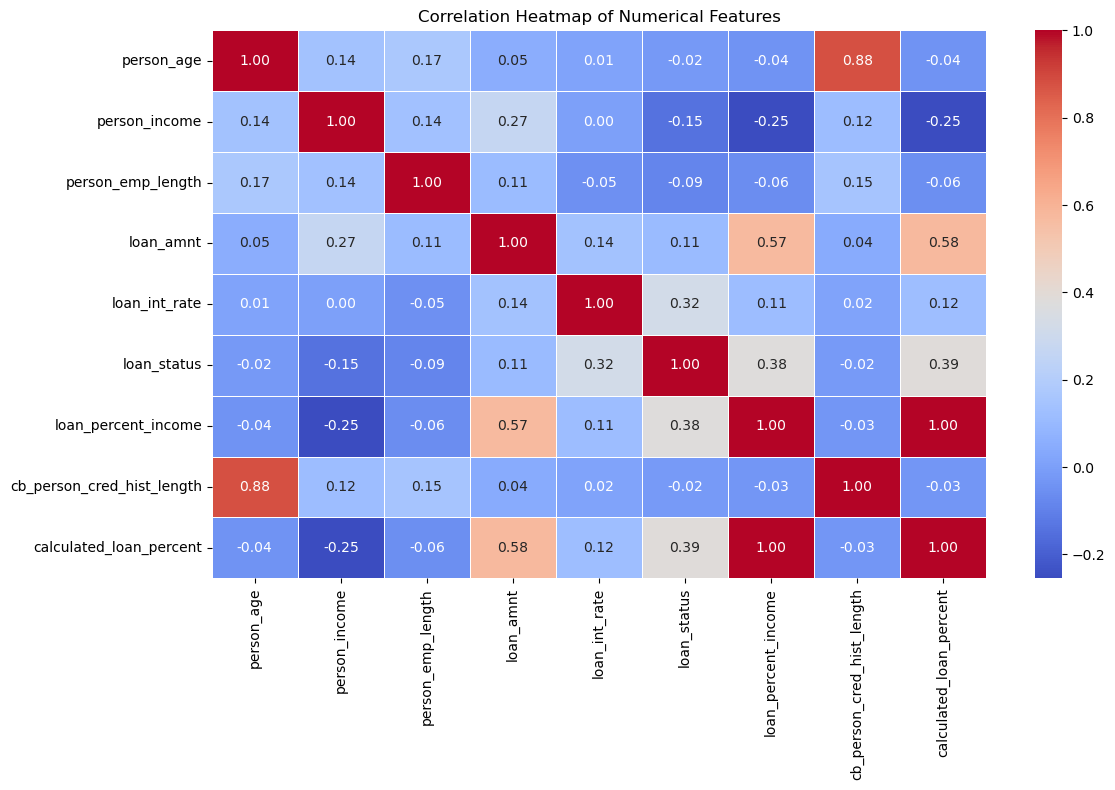

In [72]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

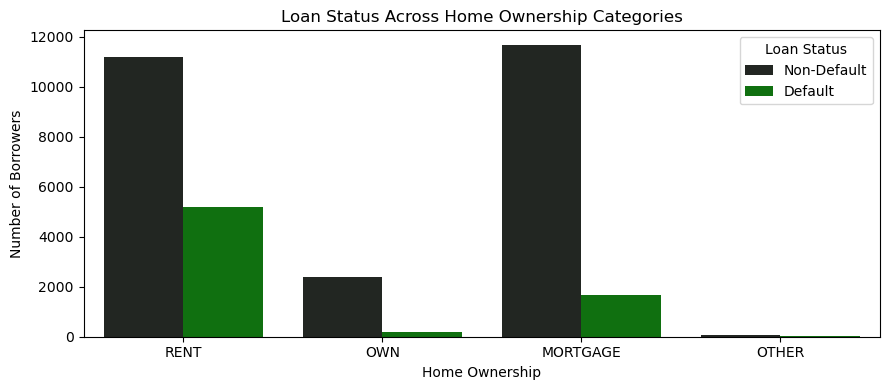

In [81]:
# Create a count plot comparing loan_status across person_home_ownership categorie

plt.figure(figsize=(9, 4))
sns.countplot(
    data=df_clean,
    x="person_home_ownership",
    hue="loan_status",
    color='g',
    linewidth=2.0
)

plt.title("Loan Status Across Home Ownership Categories")
plt.xlabel("Home Ownership")
plt.ylabel("Number of Borrowers")

plt.legend(
    title="Loan Status",
    labels=["Non-Default", "Default"]
)

plt.tight_layout()
plt.show()

In [82]:
# . Create income groups such as Low, Medium, and High using quantiles, then calculate their default rates.
# Low: Bottom 33.3% income
# Medium: Middle 33.3% income
# High: Top 33.3% income

df_clean['income_group'] = pd.qcut(
    df_clean["person_income"],
    q=3,
    labels=["Low", "Medium", "High"]
)
income_default = df_clean.groupby("income_group", observed=True).agg(
    total_borrowers=("loan_status", "count"),
    defaults=("loan_status", "sum"),
    default_rate=("loan_status", "mean")
)

income_default["default_rate"] = income_default["default_rate"] * 100

income_default

,total_borrowers,defaults,default_rate
income_group,,,
Low,10814,3909,36.147586
Medium,11132,2013,18.083004
High,10470,1167,11.146132


In [85]:
# Create a pivot table showing default rates for loan_grade versus person_home_ownership.
pivot_table = pd.pivot_table(
    df_clean,
    values="loan_status",
    index="loan_grade",
    columns="person_home_ownership",
    aggfunc="mean"
)

pivot_table = pivot_table * 100

pivot_table

person_home_ownership,MORTGAGE,OTHER,OWN,RENT
loan_grade,,,,
A,4.392765,11.538462,7.088332,17.503455
B,8.022851,15.151515,4.265997,24.100524
C,14.273010,35.294118,6.300813,26.576087
D,45.619835,55.000000,6.428571,73.791469
E,47.633136,75.000000,54.385965,75.535714
F,62.886598,100.000000,53.333333,77.952756
G,100.000000,NaN,100.000000,96.428571


- Find borrowers with high loan_percent_income and calculate their default rate. Clearly define your threshold.

#### Step 1: Define the threshold
I am choosing threshold 0.30 (30%)
For example:
  - Annual income = Rs. 1,000,000
  - Loan amount = Rs. 350,000
  - Loan-to-income ratio = 0.35 (35%)
  - This borrower qualifies as High.

#### Step 2: Filter high loan-to-income borrowers

In [87]:
high_loan_income = df_clean[
    df_clean["loan_percent_income"] >= 0.30
]
high_loan_income.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,Age_Group,calculated_loan_percent,income_group
0,22.0,59000,RENT,NaN,PERSONAL,D,35000,16.02,1,0.59,Y,3,20-25,0.593220,Medium
2,25.0,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3,20-25,0.572917,Low
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2,20-25,0.534351,Medium
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4,20-25,0.643382,Medium
6,26.0,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3,26-35,0.453956,High


#### Step 3: Calculate default rate

In [88]:
total_borrowers = len(high_loan_income)

defaults = high_loan_income["loan_status"].sum()

default_rate = (
    defaults / total_borrowers
) * 100

print("Total High Loan-to-Income Borrowers:", total_borrowers)
print("Total Defaults:", defaults)
print("Default Rate:", round(default_rate, 2), "%")

Total High Loan-to-Income Borrowers: 4267
Total Defaults: 2798
Default Rate: 65.57 %


_________________________
### Identify the five categories or segments with the highest default rates, ensuring each has a reasonable number of loans.

##### Step 1: Analyze categories
I am analyzing these categories 
- loan_grade
- person_home_ownership
- loan_intent
- cb_person_default_on_file

In [89]:
categorical_columns = [
    "loan_grade",
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
]
results = []
for col in categorical_columns:
    segment_data = df_clean.groupby(col).agg(
        total_loans=("loan_status", "count"),
        defaults=("loan_status", "sum"),
        default_rate=("loan_status", "mean")
    )

    segment_data["default_rate"] *= 100

    segment_data = segment_data[
        segment_data["total_loans"] >= 100
    ]
    segment_data = segment_data.reset_index()
    segment_data = segment_data.rename(
        columns={col: "segment"}
    )
    segment_data["category"] = col
    results.append(segment_data)

##### Step 2: Combine all categories

In [90]:
all_segments = pd.concat(results, ignore_index=True)

top_5_segments = all_segments.sort_values(
    by="default_rate",
    ascending=False
).head(5)

top_5_segments

,segment,total_loans,defaults,default_rate,category
5,F,241,170,70.539419,loan_grade
4,E,963,621,64.485981,loan_grade
3,D,3620,2138,59.060773,loan_grade
17,Y,5730,2170,37.870855,cb_person_default_on_file
9,RENT,16378,5177,31.609476,person_home_ownership


##### Step 4: Visualize top 5 segments

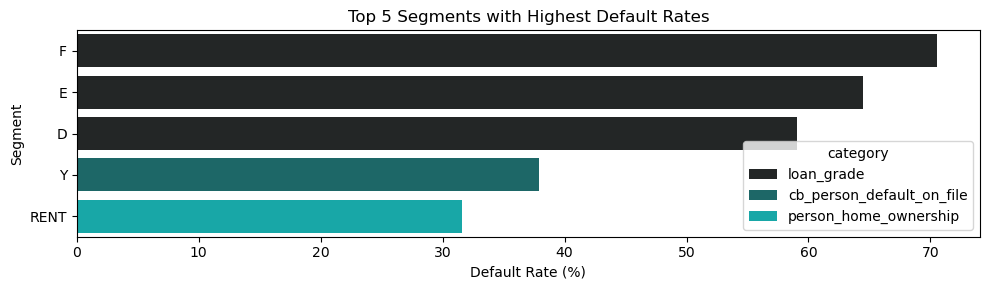

In [96]:
plt.figure(figsize=(10, 3))

sns.barplot(
    data=top_5_segments,
    x="default_rate",
    y="segment",
    hue="category",
    color='c'
    
)

plt.title("Top 5 Segments with Highest Default Rates")
plt.xlabel("Default Rate (%)")
plt.ylabel("Segment")

plt.tight_layout()
plt.show()

In [97]:
df_clean.to_csv("cleaned_bank_loan_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
